# 4.1 Sborové učení, ansámbly - cvičení

Na tomto cvičení si procvičíme následující prvky sborového cvičení:
* Hlasovací klasifikátory
  * Porovnání klasifikátoru pevné a měkké volby
* Bootstrap aggregating
* Důležitost příznaků

In [1]:
import numpy as np
import matplotlib
import matplotlib.pyplot as plt

np.random.seed(23)

## Hlasovací klasifikátor

In [2]:
# vygenerujne si trenovaci dataset
from sklearn.datasets import make_moons
from sklearn.model_selection import train_test_split

X, y = make_moons(n_samples=500, noise=0.3, random_state=42)
X_train, X_test, y_train, y_test = train_test_split(X, y, random_state=42)

In [3]:
print(X.shape)
print(y.shape)

(500, 2)
(500,)


In [4]:
# tridy
np.unique(y)

array([0, 1])

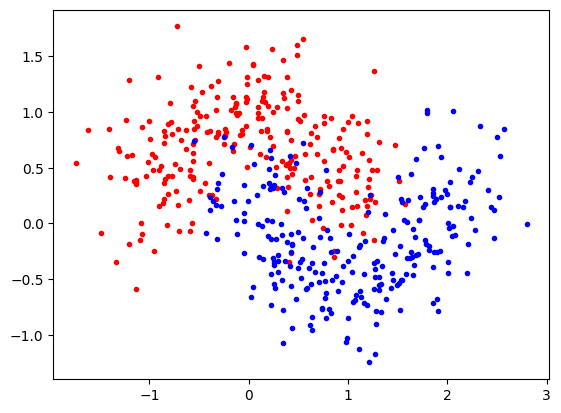

In [5]:
# vizualizace dat 
plt.plot(X[(y==0),0], X[(y==0),1], 'r.')
plt.plot(X[(y==1),0], X[(y==1),1], 'b.')

### Klasifikátor pevné volby

In [6]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC

from sklearn.ensemble import VotingClassifier

log_reg = LogisticRegression(random_state=42)
rnd_for = RandomForestClassifier(n_estimators=10, random_state=42)
svm_svc = SVC(random_state=42)


voting = VotingClassifier(
    estimators=[('lr', log_reg), ('rf', rnd_for), ('svc', svm_svc)],
    voting='hard'
)

voting.fit(X_train, y_train)

VotingClassifier(estimators=[('lr', LogisticRegression(random_state=42)),
                             ('rf',
                              RandomForestClassifier(n_estimators=10,
                                                     random_state=42)),
                             ('svc', SVC(random_state=42))])

LogisticRegression :  0.864
RandomForestClassifier :  0.872
SVC :  0.896
VotingClassifier :  0.904


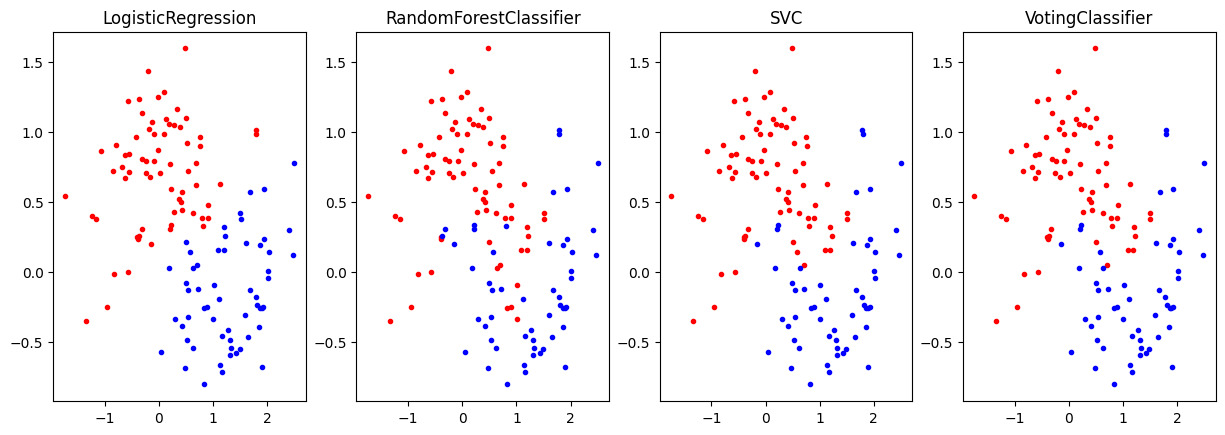

In [7]:
from sklearn.metrics import accuracy_score

models = (log_reg, rnd_for, svm_svc, voting)
fig, axes = plt.subplots(1, len(models))
fig.set_figwidth(15)

for i, clf in enumerate(models):
    clf.fit(X_train, y_train)
    y_pred = clf.predict(X_test)
    axes[i].plot(X_test[(y_pred==0),0], X_test[(y_pred==0),1], 'r.')
    axes[i].plot(X_test[(y_pred==1),0], X_test[(y_pred==1),1], 'b.')
    axes[i].set_title(clf.__class__.__name__)
    print(clf.__class__.__name__,': ', accuracy_score(y_test, y_pred))

### Klasifikátor měkké volby

In [8]:
log_reg = LogisticRegression(random_state=42)
rnd_for = RandomForestClassifier(n_estimators=10, random_state=42)
svm_svc = SVC(probability=True, random_state=42)

# voting=soft
voting_clf = VotingClassifier(
    estimators=[('lr', log_reg), ('rf', rnd_for), ('svc', svm_svc)],
    voting='soft'
)

voting_clf.fit(X_train, y_train)

VotingClassifier(estimators=[('lr', LogisticRegression(random_state=42)),
                             ('rf',
                              RandomForestClassifier(n_estimators=10,
                                                     random_state=42)),
                             ('svc', SVC(probability=True, random_state=42))],
                 voting='soft')

LogisticRegression :  0.864
RandomForestClassifier :  0.872
SVC :  0.896
VotingClassifier :  0.904


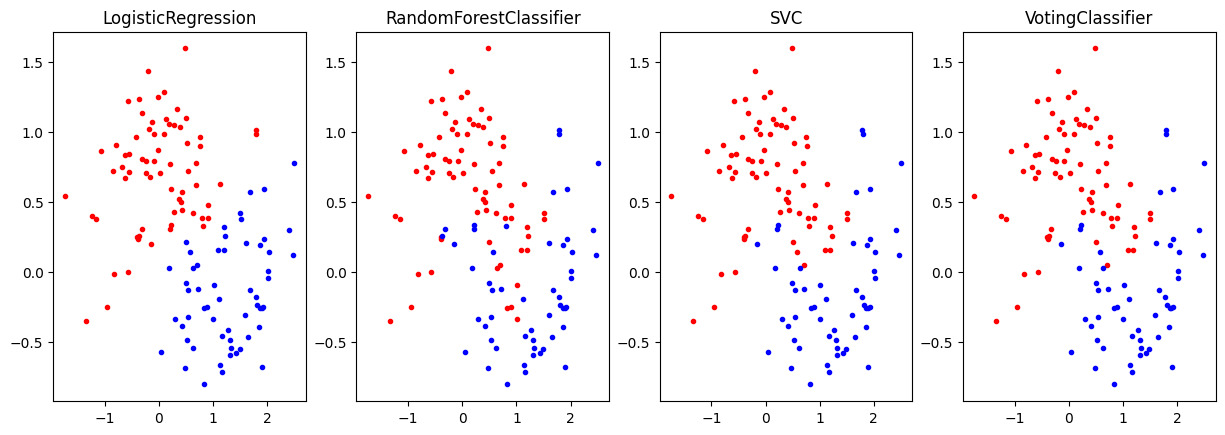

In [9]:
models = (log_reg, rnd_for, svm_svc, voting)
fig, axes = plt.subplots(1, len(models))
fig.set_figwidth(15)

for i, clf in enumerate(models):
    clf.fit(X_train, y_train)
    y_pred = clf.predict(X_test)
    axes[i].plot(X_test[(y_pred==0),0], X_test[(y_pred==0),1], 'r.')
    axes[i].plot(X_test[(y_pred==1),0], X_test[(y_pred==1),1], 'b.')
    axes[i].set_title(clf.__class__.__name__)
    print(clf.__class__.__name__,': ', accuracy_score(y_test, y_pred))

## Bootstrap aggregating (Bagging)

In [10]:
from sklearn.ensemble import BaggingClassifier
from sklearn.tree import DecisionTreeClassifier

dt = DecisionTreeClassifier(random_state=42)

bagging = BaggingClassifier(
    dt, n_estimators=500, max_samples=100, bootstrap=True, n_jobs=-1,
    random_state=42
)

pasting = BaggingClassifier(
    dt, n_estimators=500, max_samples=100, bootstrap=False, n_jobs=-1,
    random_state=42
)

bagging.fit(X_train, y_train)
pasting.fit(X_train, y_train)

BaggingClassifier(bootstrap=False,
                  estimator=DecisionTreeClassifier(random_state=42),
                  max_samples=100, n_estimators=500, n_jobs=-1,
                  random_state=42)

DecisionTreeClassifier :  0.856
BaggingClassifier :  0.904
BaggingClassifier :  0.92


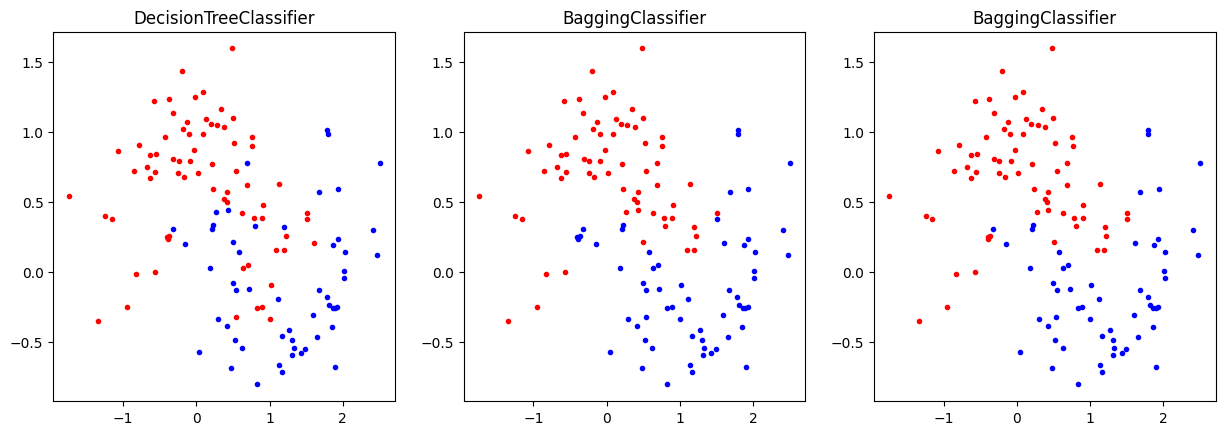

In [11]:
models = (dt, bagging, pasting)
fig, axes = plt.subplots(1, len(models))
fig.set_figwidth(15)

for i, clf in enumerate(models):
    clf.fit(X_train, y_train)
    y_pred = clf.predict(X_test)
    axes[i].plot(X_test[(y_pred==0),0], X_test[(y_pred==0),1], 'r.')
    axes[i].plot(X_test[(y_pred==1),0], X_test[(y_pred==1),1], 'b.')
    axes[i].set_title(clf.__class__.__name__)
    print(clf.__class__.__name__,': ', accuracy_score(y_test, y_pred))

### Náhodné lesy

In [12]:
from sklearn.ensemble import RandomForestClassifier

rnd_for = RandomForestClassifier(
    n_estimators=500, max_samples=100, n_jobs=-1, max_features=1.0,
    random_state=42
)

BaggingClassifier :  0.904
RandomForestClassifier :  0.904


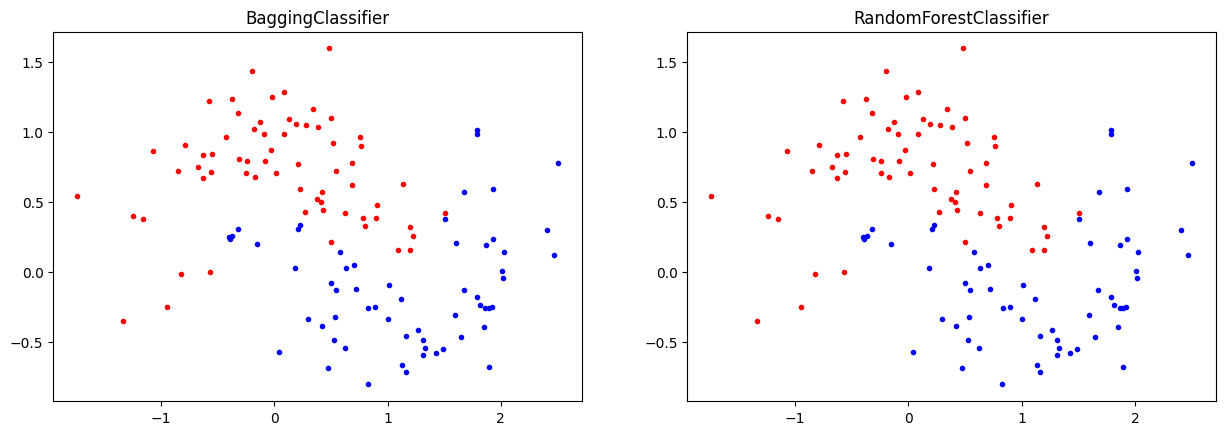

In [13]:
models = (bagging, rnd_for)
fig, axes = plt.subplots(1, len(models))
fig.set_figwidth(15)

for i, clf in enumerate(models):
    clf.fit(X_train, y_train)
    y_pred = clf.predict(X_test)
    axes[i].plot(X_test[(y_pred==0),0], X_test[(y_pred==0),1], 'r.')
    axes[i].plot(X_test[(y_pred==1),0], X_test[(y_pred==1),1], 'b.')
    axes[i].set_title(clf.__class__.__name__)
    print(clf.__class__.__name__,': ', accuracy_score(y_test, y_pred))

### Out-of-Bag přesnost

In [14]:
bagging = BaggingClassifier(
    dt, n_estimators=500, max_samples=100, bootstrap=True, n_jobs=-1, 
    oob_score=True, random_state=42
)

bagging.fit(X_train, y_train)

print(bagging.oob_score_) 

0.9253333333333333


## Důležitost příznaků

In [15]:
from sklearn.datasets import fetch_openml

mnist = fetch_openml('mnist_784', version=1)

In [16]:
mnist.target

0        5
1        0
2        4
3        1
4        9
        ..
69995    2
69996    3
69997    4
69998    5
69999    6
Name: class, Length: 70000, dtype: category
Categories (10, object): ['0', '1', '2', '3', ..., '6', '7', '8', '9']

In [17]:
mnist.target = mnist.target.astype(np.int64)

In [18]:
mnist.data.head()

,pixel1,pixel2,pixel3,pixel4,pixel5,pixel6,pixel7,pixel8,pixel9,pixel10,...,pixel775,pixel776,pixel777,pixel778,pixel779,pixel780,pixel781,pixel782,pixel783,pixel784
0,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


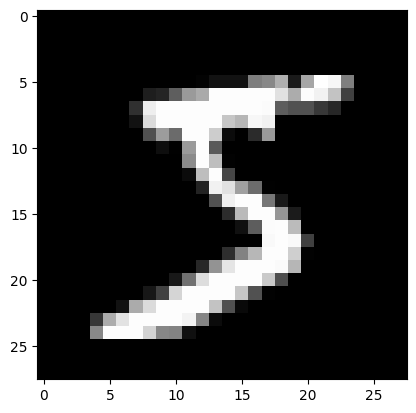

In [19]:
plt.imshow(mnist.data.loc[0].values.reshape(28, 28), cmap=matplotlib.cm.gray, interpolation="nearest")

In [20]:
rnd_for = RandomForestClassifier(n_estimators=10, random_state=42)
rnd_for.fit(mnist["data"], mnist["target"])

RandomForestClassifier(n_estimators=10, random_state=42)

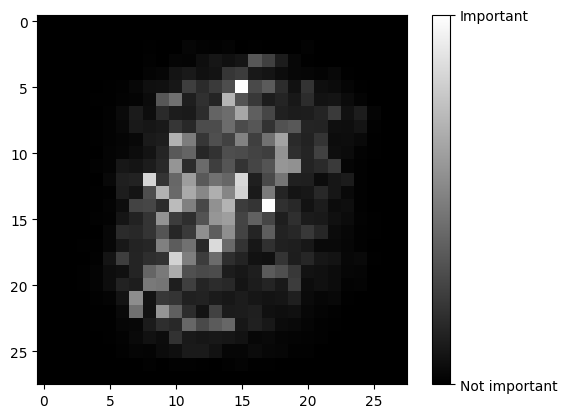

In [21]:
plt.imshow(rnd_for.feature_importances_.reshape(28, 28), cmap=matplotlib.cm.gray, interpolation="nearest")
# plt.axis("off")

cbar = plt.colorbar(ticks=[rnd_for.feature_importances_.min(), rnd_for.feature_importances_.max()])
cbar.ax.set_yticklabels(['Not important', 'Important'])

plt.show()

## AdaBoost

In [22]:
from sklearn.ensemble import AdaBoostClassifier

In [23]:
ada = AdaBoostClassifier(
    DecisionTreeClassifier(max_depth=1), algorithm='SAMME', n_estimators=100, learning_rate=0.5,
    random_state=42
)

RandomForestClassifier :  0.872
AdaBoostClassifier :  0.896


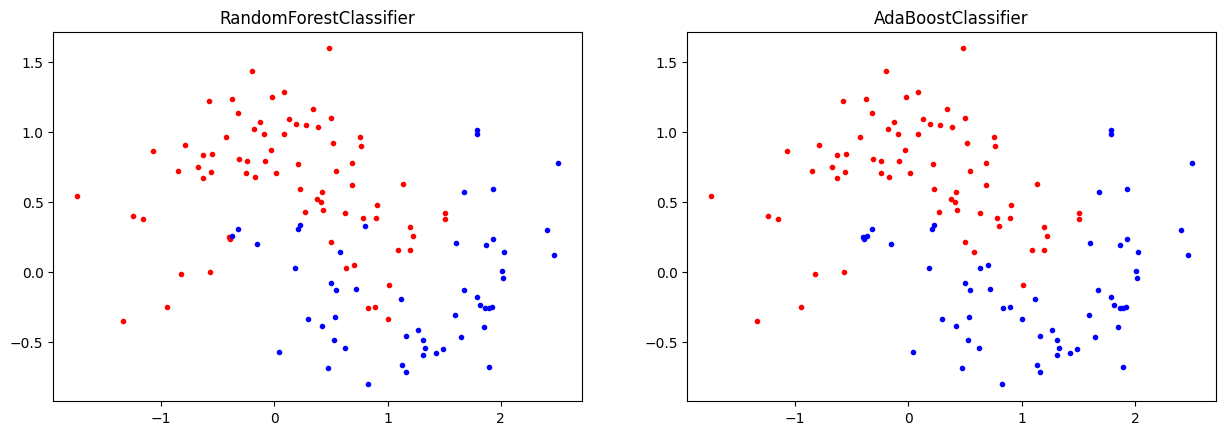

In [24]:
models = (rnd_for, ada)
fig, axes = plt.subplots(1, len(models))
fig.set_figwidth(15)

for i, clf in enumerate(models):
    clf.fit(X_train, y_train)
    y_pred = clf.predict(X_test)
    axes[i].plot(X_test[(y_pred==0),0], X_test[(y_pred==0),1], 'r.')
    axes[i].plot(X_test[(y_pred==1),0], X_test[(y_pred==1),1], 'b.')
    axes[i].set_title(clf.__class__.__name__)
    print(clf.__class__.__name__,': ', accuracy_score(y_test, y_pred))